# Descriptive Implementation of Nearest Centroid Classifier

Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Reading Dataset

In [2]:
df = pd.read_csv("CatsAndDogs.csv")

feature_columns = ['Height', 'Weight', 'Length']  
target_column = 'Animal'

Finding outliers 

In [3]:
def remove_outliers_iqr(data, feature_cols, target_col):
    cleaned_dfs = []
    
    # Process each class separately so we don't accidentally remove valid group boundaries
    for cls in data[target_col].unique():
        class_subset = data[data[target_col] == cls]
        
        for col in feature_cols:
            Q1 = class_subset[col].quantile(0.25)
            Q3 = class_subset[col].quantile(0.75)
            IQR = Q3 - Q1
            
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            
            # Keep only rows within bounds for this feature
            class_subset = class_subset[(class_subset[col] >= lower_bound) & (class_subset[col] <= upper_bound)]
            
        cleaned_dfs.append(class_subset)
        
    return pd.concat(cleaned_dfs).reset_index(drop=True)

Cleaning data

In [11]:
df_clean = remove_outliers_iqr(df, feature_columns, target_column)
print(f"Original rows: {len(df)} | Rows used for training (no outliers): {len(df_clean)}")

X_train = df_clean[feature_columns].values
y_train = df_clean[target_column].values

Original rows: 44 | Rows used for training (no outliers): 40


Finding the Centroids

In [12]:
unique_classes = np.unique(y_train)
centroids = {}

for cls in unique_classes:
    class_samples = X_train[y_train == cls]
    centroids[cls] = np.mean(class_samples, axis=0)

print("\nComputed Class Centroids:")
for cls, centroid in centroids.items():
    print(f"Class {cls}: {centroid}")


Computed Class Centroids:
Class 0: [29.7   6.1  36.05]
Class 1: [33.85  8.5  40.85]


Predicting the Class

In [13]:
def predict_nearest_centroid(X_data, centroids):
    predictions = []
    for sample in X_data:
        min_dist = float('inf')
        best_class = None
        for cls, centroid in centroids.items():
            dist = np.sqrt(np.sum((sample - centroid) ** 2))
            if dist < min_dist:
                min_dist = dist
                best_class = cls
        predictions.append(best_class)
    return np.array(predictions)

In [19]:
print("\n--- Predict Custom Data Point ---")
try:
    user_input = [30,5,27]
    #for col in feature_columns:
        # val = float(input(f"Enter value for {col}: "))
        
    user_array = np.array([user_input])
    predicted_class = predict_nearest_centroid(user_array, centroids)[0]
    
    print(f"\nPredicted Class for your input: {predicted_class}")
except ValueError:
    print("Invalid input! Please enter numeric values only.")
    user_array = None


--- Predict Custom Data Point ---

Predicted Class for your input: 0


Plotting the Data

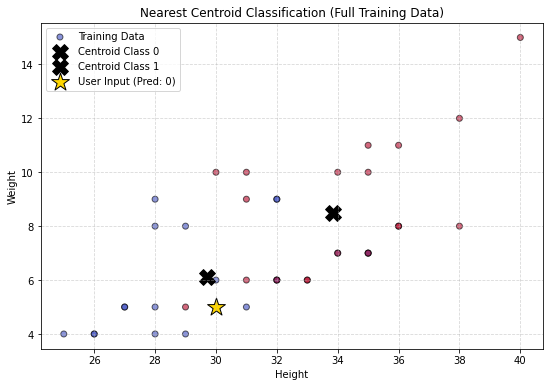

In [20]:
plt.figure(figsize=(9, 6))

# Plot all training points
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', alpha=0.6, edgecolor='k', label='Training Data')

# Plot the calculated centroids
for cls, centroid in centroids.items():
    plt.scatter(centroid[0], centroid[1], marker='X', s=250, c='black', label=f'Centroid Class {cls}')

# Plot user input point if successfully provided
if 'user_array' in locals() and user_array is not None:
    plt.scatter(user_array[0, 0], user_array[0, 1], marker='*', s=350, c='gold', edgecolor='black', label=f'User Input (Pred: {predicted_class})')

plt.title('Nearest Centroid Classification (Full Training Data)')
plt.xlabel(feature_columns[0])
plt.ylabel(feature_columns[1])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()